# 4. The app

The prototype is a Streamlit app, so it runs in a browser and not inside this notebook. This notebook shows how to start it and checks that it has the right model.
It also shows how the numbers on screen are calculated. Input: latitude, longitude and start month. Output: 12 monthly maps, class shares, and change in percentage points.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "lulc").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
RES = ROOT / "results"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "axes.grid": False})

# Where the exported data and full runs live. Set LULC_BASE to your own folder. Not needed to read or re-run this notebook.
BASE = os.environ.get("LULC_BASE", "/home/jovyan/vault/lulc" if Path("/home/jovyan/vault/lulc").is_dir() else str(ROOT / "data"))
OUT, RUNS, RUNS_MY = f"{BASE}/raw", f"{BASE}/runs", f"{BASE}/runs_multiyear"
PROJECT = os.environ.get("EE_PROJECT", "")     # your own Earth Engine project; no ID is stored in the repo
V12 = "V12_window3_balanced_stats"             # the shipped model

RUN_APP = False     # True re-runs the slow steps below. They need Earth Engine and/or a GPU. Left False, nothing is downloaded or trained.
print("repo:", ROOT.name, "| data folder found:", Path(OUT).is_dir(), "|", "RUN_APP =", RUN_APP)

repo: sar-lulc | data folder found: True | RUN_APP = False


## What you need
1. `pip install -r requirements.txt && pip install -e .`
2. `weights/final_model.pt` and `weights/ood_reference.json` (download link in the README). Not stored in git: the file is 294 MB.
3. To open saved runs offline: the `saved_runs/` folder (download link in the README). No Earth Engine account is needed for this.
4. To run a new place: your own free Earth Engine project (`earthengine authenticate`, then set `EE_PROJECT` or type it in the sidebar).

## Check the model
Confirms the weights are the shipped multi-year ensemble by comparing each seed's validation score with its saved model card.

In [2]:
import torch
w = ROOT / "weights" / "final_model.pt"
expected = sorted(json.loads(p.read_text())["best_val_miou"] for p in (RES / "runs_multiyear" / V12).glob("seed*/model_card.json"))
if not w.exists():
    print("weights/final_model.pt not found. Download it (see the README). Expected validation scores per seed:", [round(x, 4) for x in expected])
else:
    cards = torch.load(w, map_location="cpu")["cards"]
    got = sorted(c["best_val_miou"] for c in cards)
    print(len(cards), "seeds | shipped multi-year model:", np.allclose(got, expected), "|", [round(x, 4) for x in got])
print("ood_reference.json present (needed for the area warning):", (ROOT / "weights" / "ood_reference.json").exists())
saved = sorted((ROOT / "saved_runs").glob("*.pkl.gz")) if (ROOT / "saved_runs").exists() else []
print(len(saved), "saved runs for offline replay:", [p.stem for p in saved[:8]])

3 seeds | shipped multi-year model: True | [0.6129, 0.6166, 0.6175]
ood_reference.json present (needed for the area warning): True
3 saved runs for offline replay: ['14_0000_8_0000_jan_2021.pkl', '48_6520_8_3496_jan_2025.pkl', 'heidelberg_germany_city_jan_2021.pkl']


## Start it
In a terminal, from the repo root: `streamlit run prototype/app.py`, then open http://localhost:8501. Or set `RUN_APP = True` above and run this cell; it keeps running until you stop it.

In [3]:
if RUN_APP:
    !streamlit run prototype/app.py

## A full run
| Step | Where | What to look at |
|---|---|---|
| 1 | Sidebar | Choose a place and a start month, then press Run. Or choose "Saved run (offline)" |
| 2 | Map viewer | The class map over a satellite photo. Click a pixel to see its class in every month |
| 3 | Change | The month-to-month table, first against last month, and the verdict against the noise floor |
| 4 | Class statistics | The share of each class per month, with the spread between seeds |
| 5 | Validation (independent maps) | Agreement with WorldCover and Esri, for 2021 |
| 6 | Model and limits | The test scores and what not to trust |

In [4]:
from lulc import proto
display(pd.DataFrame([{"place": k, "lat": v[0], "lon": v[1], "year": v[2], "start month": v[3]} for k, v in proto.DEMOS.items()]))

,place,lat,lon,year,start month
0,"Heidelberg, Germany (city)",49.4000,8.6700,2021,1
1,"Tonle Sap, Cambodia (seasonal lake)",13.0000,104.0500,2021,1
2,"Inner Niger delta, Mali (flood plain)",15.2000,-4.2000,2021,1
3,"Poyang Lake, China (seasonal lake)",29.1000,116.2500,2021,1
4,"Punjab, India (double-cropped fields)",30.9000,75.8000,2021,1
5,"Control: Prague, Czechia (built-up city, shoul...",50.0755,14.4378,2021,1


Demo places were chosen for visible change and radar coverage, so they are not evidence of accuracy. Test scores are in `03_train_validate_test.ipynb`.

## How the numbers are calculated
Class shares use only pixels valid in all months of the run, so a missing pixel cannot look like land-use change. Change is a difference of shares, in percentage points.
A small example with made-up maps of 4 pixels (255 = no radar, so that pixel is left out of every month):

In [5]:
from lulc.stats import monthly_change_table
maps = [np.array([[0, 0], [2, 3]]), np.array([[0, 2], [2, 3]]), np.array([[0, 2], [255, 3]])]
t = monthly_change_table(maps, ["Jan", "Feb", "Mar"])
for name, x in (("Share of valid pixels (%)", t.percent), ("Month-to-month change (pp)", t.delta)):
    print(name); display(x.round(1))
print("First to last month (pp):", t.total_change.round(1).to_dict())

Share of valid pixels (%)


,Tree cover,Grass/shrub,Cropland,Built-up,Bare,Water
Jan,66.7,0.0,0.0,33.3,0.0,0.0
Feb,33.3,0.0,33.3,33.3,0.0,0.0
Mar,33.3,0.0,33.3,33.3,0.0,0.0


Month-to-month change (pp)


,Tree cover,Grass/shrub,Cropland,Built-up,Bare,Water
Jan,NaN,NaN,NaN,NaN,NaN,NaN
Feb,-33.3,0.0,33.3,0.0,0.0,0.0
Mar,0.0,0.0,0.0,0.0,0.0,0.0


First to last month (pp): {'Tree cover': -33.3, 'Grass/shrub': 0.0, 'Cropland': 33.3, 'Built-up': 0.0, 'Bare': 0.0, 'Water': 0.0}


## Noise floor
On land that both annual maps call stable, a change should be zero, so anything reported there is noise. The app compares every change with these values, measured for the shipped model on 9 test regions in 2021.
They are averages over regions, not upper limits, so a stable place can still exceed them.

In [6]:
display(pd.DataFrame([proto.NOISE_FLOOR]).T.rename(columns={0: "value"}))
measured = pd.read_csv(RES / "tables" / "false_change.csv").set_index("maps")
display(measured)
assert abs(measured.loc["model", "flip_rate_pct"] - proto.NOISE_FLOOR["flip_rate_raw_pct"]) < 0.01      # the app and the test must agree
assert abs(measured.loc["model+majority3", "flip_rate_pct"] - proto.NOISE_FLOOR["flip_rate_smoothed_pct"]) < 0.01
print("App and test agree.")

,value
monthly_churn_raw_pp,1.61
monthly_churn_smoothed_pp,0.62
net_raw_pp,2.27
net_smoothed_pp,1.48
seed_spread_pp,2.23
flip_rate_raw_pct,2.61
flip_rate_smoothed_pct,1.0
source,"false-change test on 9 test regions, V12 train..."


,flip_rate_pct,monthly_churn_pp,net_total_change_pp
maps,,,
dynamic_world,6.79,4.27,8.30
model,2.61,1.61,2.27
model+majority3,1.00,0.62,1.48


App and test agree.


## Case study: Heidelberg, January 2021
The app's check of the urban case study against the independent WorldCover and Esri maps.

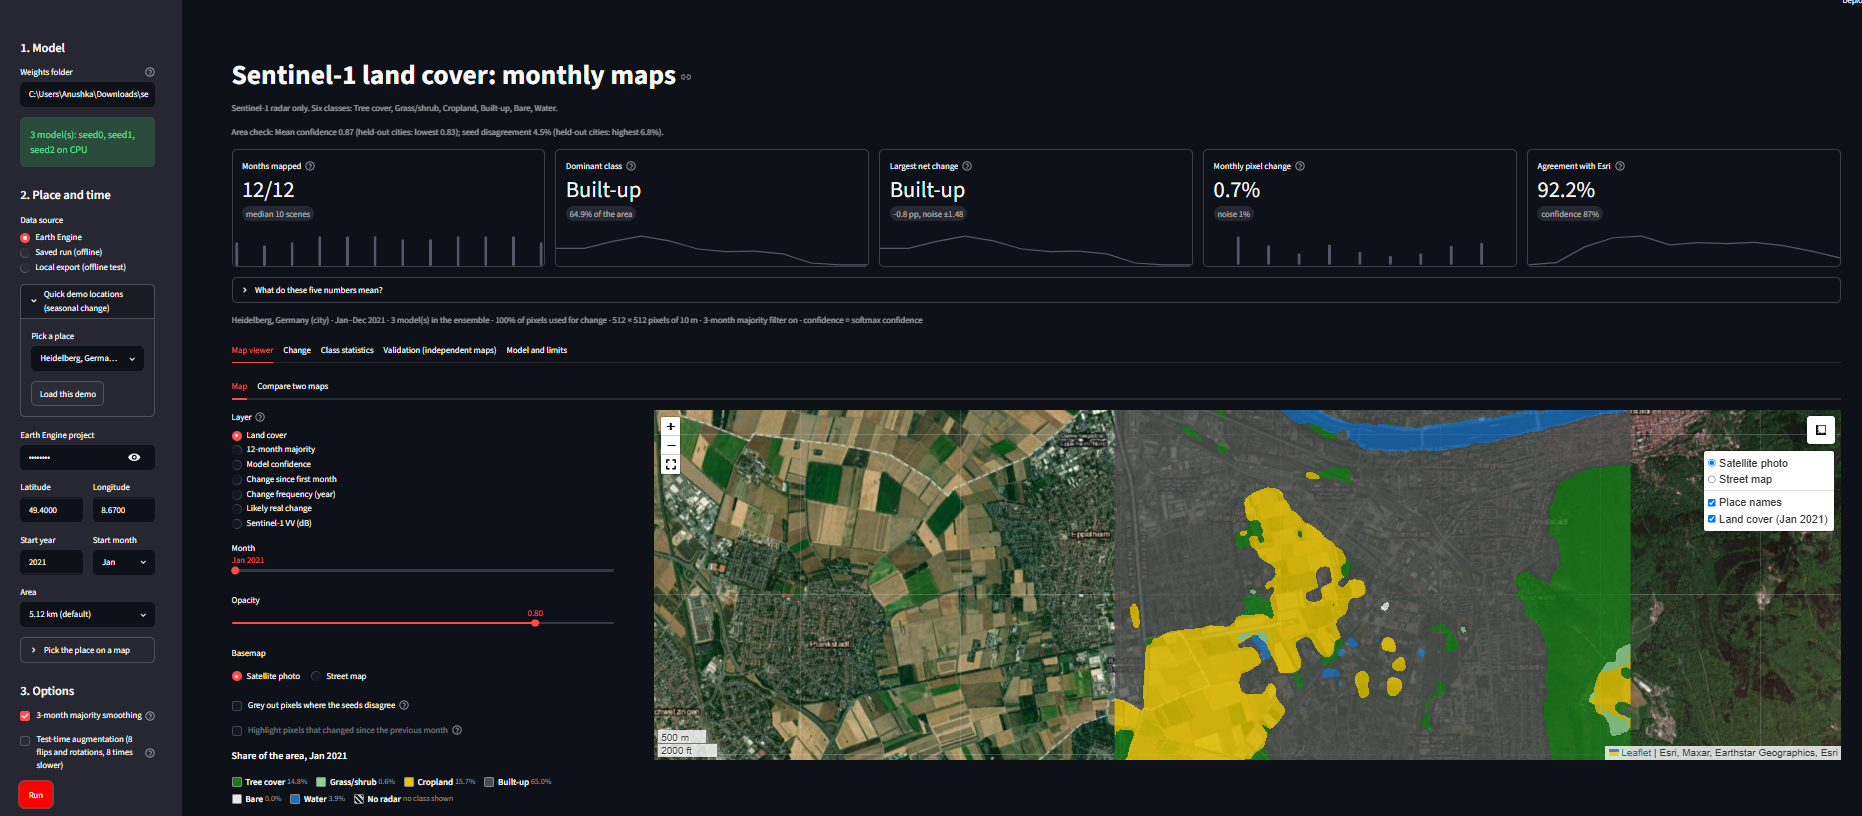

In [7]:
from IPython.display import Image
f = ROOT / "docs" / "figures" / "heidelberg_2021_independent_check.png"
display(Image(str(f))) if f.exists() else print("Not found:", f)

**Next:** `05_experiments.ipynb`.